<a href="https://colab.research.google.com/github/LorranaAraujo/Previsao_Financial_Risk/blob/main/TCC_Previsao_Riscos_Financeiros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Previsão de Riscos Financeiros com Data Science e Machine Learning

**Autora:** Lorrana Evelyn de Araújo Pereira  
**Curso:** Tecnologia em Gestão de Dados — UFPI / CEAD  


---



| # | Etapa | Descrição |
|---|-------|-----------|
| 1 | **Instalação & Imports** | Bibliotecas necessárias |
| 2 | **Coleta de Dados** | Yahoo Finance via yfinance |
| 3 | **EDA** | Análise Exploratória dos Dados |
| 4 | **Pré-processamento** | Limpeza, engenharia de atributos e split |
| 5 | **Modelagem** | XGBoost, LightGBM e Rede Neural |
| 6 | **Avaliação** | Métricas RMSE, MAE, R² |
| 7 | **Interpretabilidade** | SHAP e LIME |
| 8 | **Dashboard** | Visualização interativa com Plotly |




In [ ]:

!pip install yfinance xgboost lightgbm shap lime plotly ipywidgets --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 37.5 MB/s eta 0:00:00


---
## Importações


In [ ]:

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from datetime import datetime


import yfinance as yf

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import lightgbm as lgb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


import shap
import lime
import lime.lime_tabular

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'DejaVu Sans'

print(f" Imports concluídos | TensorFlow {tf.__version__} | XGBoost {xgb.__version__} | LightGBM {lgb.__version__}")

 Imports concluídos | TensorFlow 2.19.0 | XGBoost 3.2.0 | LightGBM 4.6.0


Coleta de dados no Yahoo Finance dos ativos IBOVESPA E S&P 500

Download de séries temporais diárias de ações da B3 e índices de mercado para o período de 2016 a hoje.  
Em seguida, =é calculado atributos financeiros derivados: retorno diário, volatilidade histórica e médias móveis.

In [ ]:

ATIVOS = {
    "acoes_br": ["PETR4.SA", "VALE3.SA", "ITUB4.SA", "BBDC4.SA", "ABEV3.SA"],
    "indices":  ["^BVSP", "^GSPC"],
}
DATA_INICIO = "2016-01-01"
DATA_FIM    = datetime.today().strftime("%Y-%m-%d")
INTERVALO   = "1d"
PASTA_SAIDA = "dados_coletados"

os.makedirs(PASTA_SAIDA, exist_ok=True)


def baixar_ativo(ticker, inicio, fim, intervalo):
    try:
        df = yf.download(ticker, start=inicio, end=fim,
                         interval=intervalo, progress=False, auto_adjust=True)
        if df.empty:
            print(f"  Sem dados: {ticker}")
            return None
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        df.index.name = "Data"
        df.reset_index(inplace=True)
        print(f"  {ticker:<15} {len(df)} registros  "
              f"({df['Data'].min().date()} → {df['Data'].max().date()})")
        return df
    except Exception as e:
        print(f"  {ticker}: {e}")
        return None


def engenharia_atributos(df, janela=21):
    #Adiciona retorno, volatilidade histórica e médias móveis
    df = df.copy()
    df["Retorno_Diario"]        = df["Close"].pct_change()
    df[f"Volatilidade_{janela}d"] = (
        df["Retorno_Diario"].rolling(janela).std() * np.sqrt(252)
    )
    df["MM_20d"]  = df["Close"].rolling(20).mean()
    df["MM_50d"]  = df["Close"].rolling(50).mean()
    df["RSI_14d"] = calcular_rsi(df["Close"], 14)
    df["Volume_MM20"] = df["Volume"].rolling(20).mean()
    return df


def calcular_rsi(series, periodo=14):

    delta = series.diff()
    ganho = delta.clip(lower=0).rolling(periodo).mean()
    perda = (-delta.clip(upper=0)).rolling(periodo).mean()
    rs    = ganho / perda.replace(0, np.nan)
    return 100 - (100 / (1 + rs))


dados = {}   # dicionário global: ticker → DataFrame

for categoria, tickers in ATIVOS.items():
    print(f"\n── {categoria.upper()} ──")
    pasta_cat = os.path.join(PASTA_SAIDA, categoria)
    os.makedirs(pasta_cat, exist_ok=True)

    for ticker in tickers:
        df = baixar_ativo(ticker, DATA_INICIO, DATA_FIM, INTERVALO)
        if df is not None:
            df = engenharia_atributos(df)
            nome = ticker.replace("^", "IDX_").replace(".SA", "")
            df.to_csv(os.path.join(pasta_cat, f"{nome}.csv"), index=False, encoding="utf-8-sig")
            dados[ticker] = df

print(f"\n Coleta concluída! {len(dados)} ativos carregados.")


── ACOES_BR ──
  PETR4.SA        2551 registros  (2016-01-04 → 2026-03-30)
  VALE3.SA        2551 registros  (2016-01-04 → 2026-03-30)
  ITUB4.SA        2551 registros  (2016-01-04 → 2026-03-30)
  BBDC4.SA        2551 registros  (2016-01-04 → 2026-03-30)
  ABEV3.SA        2551 registros  (2016-01-04 → 2026-03-30)

── INDICES ──
  ^BVSP           2543 registros  (2016-01-04 → 2026-03-30)
  ^GSPC           2574 registros  (2016-01-04 → 2026-03-30)

 Coleta concluída! 7 ativos carregados.


---
EDA — Análise Exploratória dos Dados

Antes de modelar, é fundamental entender a distribuição, tendências e correlações dos dados.  
Usaremos como ativo de referência o **IBOVESPA (^BVSP)** para a modelagem preditiva.

In [ ]:
#Ativo de referência para modelagem
TICKER_REF = "^BVSP"
df_ref = dados[TICKER_REF].dropna().copy()


print(f"📋 Shape: {df_ref.shape}")
print(f"📅 Período: {df_ref['Data'].min().date()} → {df_ref['Data'].max().date()}")
df_ref.tail()

📋 Shape: (2492, 12)
📅 Período: 2016-03-16 → 2026-03-30


Price,Data,Close,High,Low,Open,Volume,Retorno_Diario,Volatilidade_21d,MM_20d,MM_50d,RSI_14d,Volume_MM20
2538,2026-03-24,182509.0,182649.0,179915.0,181932.0,7563900,0.003172,0.251675,182738.60,180788.16,45.453677,10294010.0
2539,2026-03-25,185424.0,186401.0,182524.0,182529.0,9074000,0.015972,0.253325,182447.40,181233.64,58.425630,10290965.0
2540,2026-03-26,182733.0,185424.0,182570.0,185424.0,7806700,-0.014513,0.257354,182033.80,181648.84,55.427706,10241430.0
2541,2026-03-27,181557.0,183351.0,180976.0,182733.0,8073000,-0.006436,0.257781,181672.30,181977.06,51.047240,10094965.0
2542,2026-03-30,182514.0,184414.0,181560.0,181561.0,7704600,0.005271,0.256718,181332.65,182315.98,48.395639,10025685.0


In [ ]:
# Estatísticas Descritivas
colunas_num = ["Close", "Volume", "Retorno_Diario", "Volatilidade_21d", "MM_20d", "MM_50d", "RSI_14d"]
df_ref[colunas_num].describe().round(4)

Price,Close,Volume,Retorno_Diario,Volatilidade_21d,MM_20d,MM_50d,RSI_14d
count,2492.0000,2.492000e+03,2492.0000,2492.0000,2492.0000,2492.0000,2492.0000
mean,104008.1212,7.964416e+06,0.0006,0.2011,103503.0638,102642.7722,54.2755
std,27640.1524,4.134513e+06,0.0145,0.1144,27339.6468,26814.9424,16.9703
min,47763.0000,0.000000e+00,-0.1478,0.0669,45620.6500,42063.4000,4.8685
25%,83497.2500,4.085300e+06,-0.0065,0.1449,82889.4375,82070.4600,42.0757
50%,107133.0000,8.157450e+06,0.0008,0.1821,106998.5000,106469.8100,52.8319
75%,122066.5000,1.090218e+07,0.0083,0.2271,121476.0500,122405.6600,66.5678
max,191490.0000,2.602930e+07,0.1391,1.2683,187140.2000,182315.9800,99.0448


In [ ]:
#Preço de Fechamento + Médias Móveis
fig = go.Figure()

fig.add_trace(go.Scatter(x=df_ref["Data"], y=df_ref["Close"],
                         name="Fechamento", line=dict(color="#1f77b4", width=1.2)))
fig.add_trace(go.Scatter(x=df_ref["Data"], y=df_ref["MM_20d"],
                         name="MM 20d", line=dict(color="#ff7f0e", dash="dash")))
fig.add_trace(go.Scatter(x=df_ref["Data"], y=df_ref["MM_50d"],
                         name="MM 50d", line=dict(color="#2ca02c", dash="dot")))

fig.update_layout(
    title="IBOVESPA — Preço de Fechamento e Médias Móveis (2016–hoje)",
    xaxis_title="Data", yaxis_title="Pontos",
    hovermode="x unified", template="plotly_white",
    height=420, legend=dict(orientation="h", y=1.02)
)
fig.show()

In [ ]:
# volatilidade historia (21 dias)
fig2 = px.area(
    df_ref, x="Data", y="Volatilidade_21d",
    title="Volatilidade Histórica Anualizada — IBOVESPA (janela 21 dias)",
    labels={"Volatilidade_21d": "Volatilidade (anualizada)"},
    color_discrete_sequence=["#d62728"],
    template="plotly_white", height=380
)
fig2.update_traces(fillcolor="rgba(214,39,40,0.15)")
fig2.show()

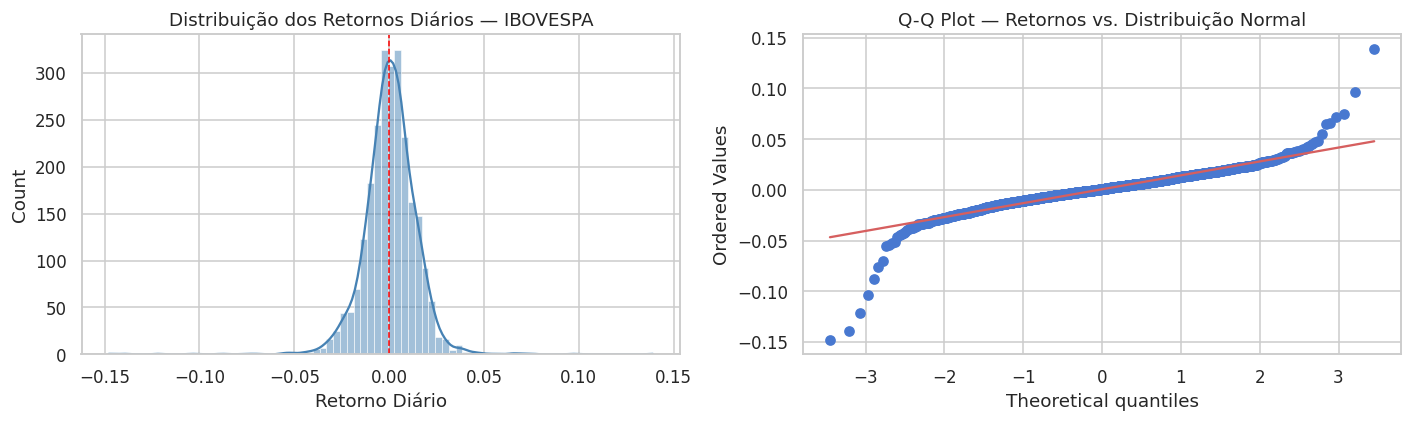

  Assimetria (skewness): -0.8359
  Curtose (kurtosis):    16.3748
  → Curtose elevada confirma caudas pesadas (leptocúrtica) — típico de séries financeiras.


In [ ]:
#ditribuição dos retornos diários
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_ref["Retorno_Diario"].dropna(), bins=80,
             kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Distribuição dos Retornos Diários — IBOVESPA")
axes[0].set_xlabel("Retorno Diário")

from scipy import stats
stats.probplot(df_ref["Retorno_Diario"].dropna(), plot=axes[1])
axes[1].set_title("Q-Q Plot — Retornos vs. Distribuição Normal")

plt.tight_layout()
plt.show()
print(f"  Assimetria (skewness): {df_ref['Retorno_Diario'].skew():.4f}")
print(f"  Curtose (kurtosis):    {df_ref['Retorno_Diario'].kurtosis():.4f}")
print("  → Curtose elevada confirma caudas pesadas (leptocúrtica) — típico de séries financeiras.")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


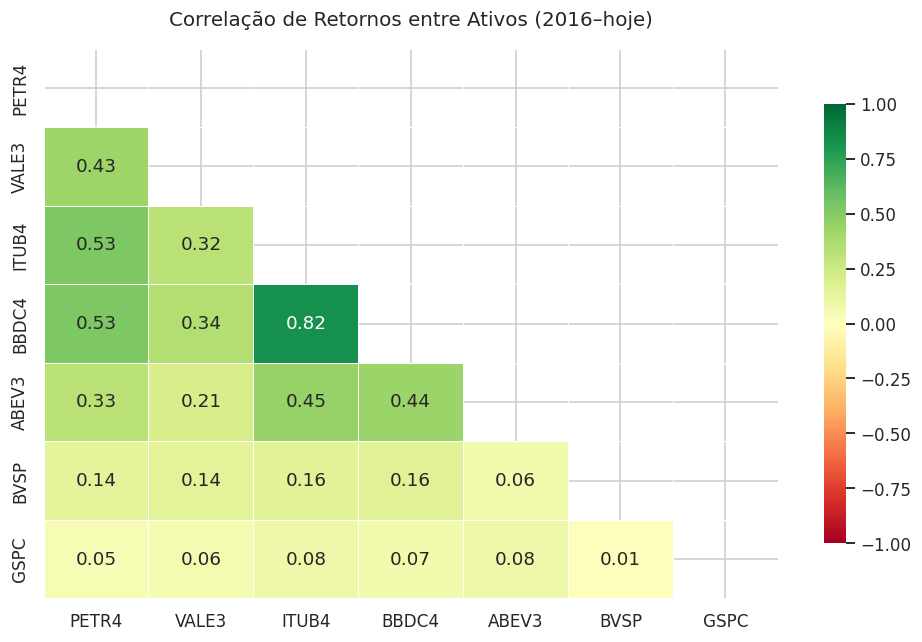

In [ ]:
#Matriz de Correlação entre Ativos
retornos = pd.DataFrame({
    ticker.replace(".SA","").replace("^",""): df["Retorno_Diario"]
    for ticker, df in dados.items()
}).dropna()

fig, ax = plt.subplots(figsize=(9, 6))
mask = np.triu(np.ones_like(retornos.corr(), dtype=bool))
sns.heatmap(retornos.corr(), annot=True, fmt=".2f", cmap="RdYlGn",
            vmin=-1, vmax=1, mask=mask, ax=ax,
            linewidths=.5, cbar_kws={"shrink": .8})
ax.set_title("Correlação de Retornos entre Ativos (2016–hoje)", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

---
Pré-processamento & Preparação para Modelagem

**Variável-alvo:** volatilidade do dia seguinte (`Volatilidade_21d` deslocada 1 período — problema de regressão).  
**Features:** atributos técnicos e derivados do dia corrente.  
**Split:** separação temporal (sem embaralhamento) para evitar *data leakage*.

In [ ]:
# ─── Definição de features e target ──────────────────────────────────────────
FEATURES = ["Close", "Volume", "Retorno_Diario", "Volatilidade_21d",
            "MM_20d", "MM_50d", "RSI_14d", "Volume_MM20"]
TARGET   = "Target_Vol"

df_model = df_ref[FEATURES + ["Data"]].copy()

# Target = volatilidade do DIA SEGUINTE (previsão 1 step à frente)
df_model[TARGET] = df_model["Volatilidade_21d"].shift(-1)
df_model.dropna(inplace=True)

X = df_model[FEATURES].values
y = df_model[TARGET].values
datas = df_model["Data"].values

# Split temporal 80 / 20
split_idx = int(len(X) * 0.80)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
datas_test       = datas[split_idx:]

# Normalização - treino
scaler  = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f"   Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")
print(f"   Features: {FEATURES}")
print(f"   Target  : Volatilidade do dia seguinte (anualizada)")

   Treino: 1992 amostras | Teste: 499 amostras
   Features: ['Close', 'Volume', 'Retorno_Diario', 'Volatilidade_21d', 'MM_20d', 'MM_50d', 'RSI_14d', 'Volume_MM20']
   Target  : Volatilidade do dia seguinte (anualizada)


---
##  Modelagem

In [ ]:

def avaliar_modelo(nome, y_real, y_pred):
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae  = mean_absolute_error(y_real, y_pred)
    r2   = r2_score(y_real, y_pred)
    print(f"  [{nome}]  RMSE: {rmse:.5f}  |  MAE: {mae:.5f}  |  R²: {r2:.4f}")
    return {"Modelo": nome, "RMSE": rmse, "MAE": mae, "R2": r2}

resultados = []

In [ ]:
# XGBoost
print("🔵 Treinando XGBoost...")
modelo_xgb = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=0
)
modelo_xgb.fit(
    X_train_s, y_train,
    eval_set=[(X_test_s, y_test)],
    verbose=False
)
pred_xgb = modelo_xgb.predict(X_test_s)
resultados.append(avaliar_modelo("XGBoost", y_test, pred_xgb))
print(" XGBoost concluído!")

🔵 Treinando XGBoost...
  [XGBoost]  RMSE: 0.01335  |  MAE: 0.00959  |  R²: 0.9002
 XGBoost concluído!


In [ ]:
# LightGBM
print("🟡 Treinando LightGBM...")
modelo_lgb = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)
modelo_lgb.fit(
    X_train_s, y_train,
    eval_set=[(X_test_s, y_test)]
)
pred_lgb = modelo_lgb.predict(X_test_s)
resultados.append(avaliar_modelo("LightGBM", y_test, pred_lgb))
print(" LightGBM concluído!")

🟡 Treinando LightGBM...
  [LightGBM]  RMSE: 0.01427  |  MAE: 0.01049  |  R²: 0.8860
 LightGBM concluído!


In [ ]:
#  Rede Neural
print("🟣 Treinando Rede Neural (MLP)...")

tf.random.set_seed(42)

modelo_nn = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)   # saída de regressão
], name="MLP_Volatilidade")

modelo_nn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)

history = modelo_nn.fit(
    X_train_s, y_train,
    validation_data=(X_test_s, y_test),
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

pred_nn = modelo_nn.predict(X_test_s, verbose=0).flatten()
resultados.append(avaliar_modelo("Rede Neural (MLP)", y_test, pred_nn))
print(f"✅ Rede Neural concluída! ({len(history.epoch)} épocas)")

🟣 Treinando Rede Neural (MLP)...
  [Rede Neural (MLP)]  RMSE: 0.01750  |  MAE: 0.01333  |  R²: 0.8286
✅ Rede Neural concluída! (85 épocas)


---
## Avaliação Comparativa dos Modelos

In [ ]:
# ─── Tabela de métricas ───────────────────────────────────────────────────────
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.sort_values("RMSE")
print("\n📊 COMPARAÇÃO DE MODELOS\n")
display(df_resultados.style
        .format({"RMSE": "{:.5f}", "MAE": "{:.5f}", "R2": "{:.4f}"})
        .highlight_min(subset=["RMSE","MAE"], color="#d4edda")
        .highlight_max(subset=["R2"],          color="#d4edda")
        .set_caption("Verde = melhor resultado"))


📊 COMPARAÇÃO DE MODELOS



,Modelo,RMSE,MAE,R2
0,XGBoost,0.01335,0.00959,0.9002
1,LightGBM,0.01427,0.01049,0.8860
2,Rede Neural (MLP),0.01750,0.01333,0.8286


In [ ]:
#  Previsão vs. Real
datas_dt = pd.to_datetime(datas_test)

fig = go.Figure()
fig.add_trace(go.Scatter(x=datas_dt, y=y_test,
                         name="Real", line=dict(color="#1f77b4", width=2)))
fig.add_trace(go.Scatter(x=datas_dt, y=pred_xgb,
                         name="XGBoost", line=dict(color="#ff7f0e", dash="dash")))
fig.add_trace(go.Scatter(x=datas_dt, y=pred_lgb,
                         name="LightGBM", line=dict(color="#2ca02c", dash="dot")))
fig.add_trace(go.Scatter(x=datas_dt, y=pred_nn,
                         name="Rede Neural", line=dict(color="#9467bd", dash="dashdot")))

fig.update_layout(
    title="Previsão de Volatilidade — Real vs. Modelos (conjunto de teste)",
    xaxis_title="Data", yaxis_title="Volatilidade (anualizada)",
    hovermode="x unified", template="plotly_white", height=450,
    legend=dict(orientation="h", y=1.02)
)
fig.show()

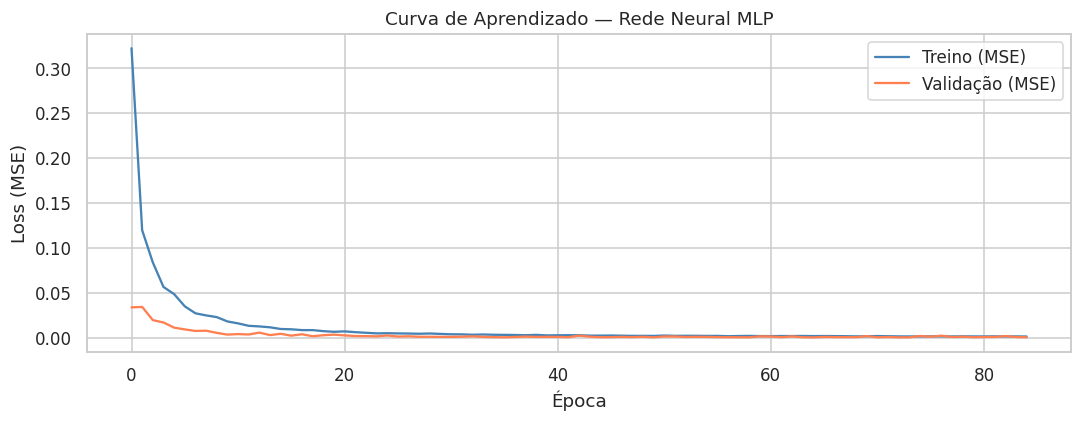

In [ ]:
#  Curva de aprendizado: Rede Neural
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.history["loss"],     label="Treino (MSE)",   color="steelblue")
ax.plot(history.history["val_loss"], label="Validação (MSE)", color="coral")
ax.set_title("Curva de Aprendizado — Rede Neural MLP")
ax.set_xlabel("Época")
ax.set_ylabel("Loss (MSE)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Validação Cruzada Temporal XGBoost
print(" Validação cruzada temporal (5 folds) — XGBoost...")
tscv  = TimeSeriesSplit(n_splits=5)
rmses = []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X), 1):
    Xtr, Xval = X[tr_idx], X[val_idx]
    ytr, yval = y[tr_idx], y[val_idx]

    sc  = StandardScaler().fit(Xtr)
    m   = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05,
                            max_depth=5, random_state=42, verbosity=0)
    m.fit(sc.transform(Xtr), ytr, verbose=False)
    pred = m.predict(sc.transform(Xval))
    rmse = np.sqrt(mean_squared_error(yval, pred))
    rmses.append(rmse)
    print(f"   Fold {fold}: RMSE = {rmse:.5f}")

print(f"\n  Média RMSE: {np.mean(rmses):.5f}  ±  {np.std(rmses):.5f}")

 Validação cruzada temporal (5 folds) — XGBoost...
   Fold 1: RMSE = 0.01605
   Fold 2: RMSE = 0.19382
   Fold 3: RMSE = 0.02251
   Fold 4: RMSE = 0.01269
   Fold 5: RMSE = 0.01069

  Média RMSE: 0.05115  ±  0.07145


---
## Interpretabilidade — SHAP & LIME

**SHAP** (*SHapley Additive exPlanations*) atribui a cada feature uma contribuição média para a previsão.  
**LIME** (*Local Interpretable Model-agnostic Explanations*) explica previsões individuais.

🔵 Calculando valores SHAP para XGBoost...


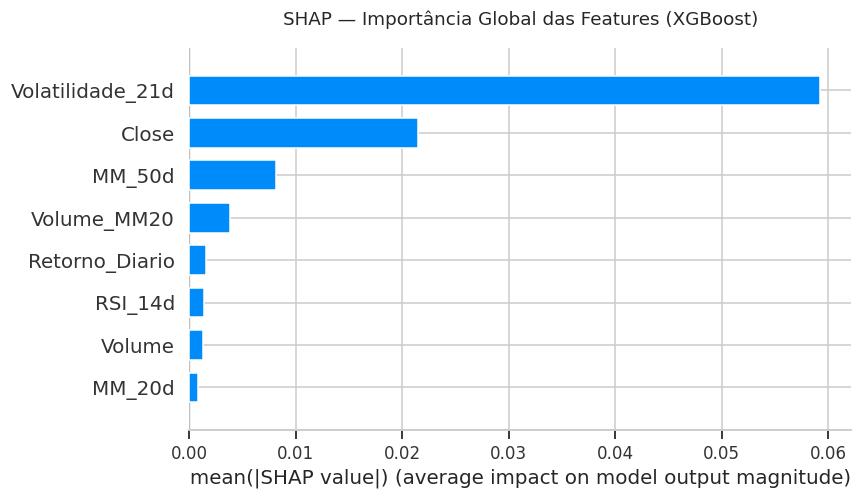

In [ ]:
#SHAP — XGBoost
print("🔵 Calculando valores SHAP para XGBoost...")
explainer_shap = shap.TreeExplainer(modelo_xgb)
shap_values    = explainer_shap.shap_values(X_test_s)

plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X_test_s, feature_names=FEATURES,
                  plot_type="bar", show=False)
plt.title("SHAP — Importância Global das Features (XGBoost)", pad=15)
plt.tight_layout()
plt.show()

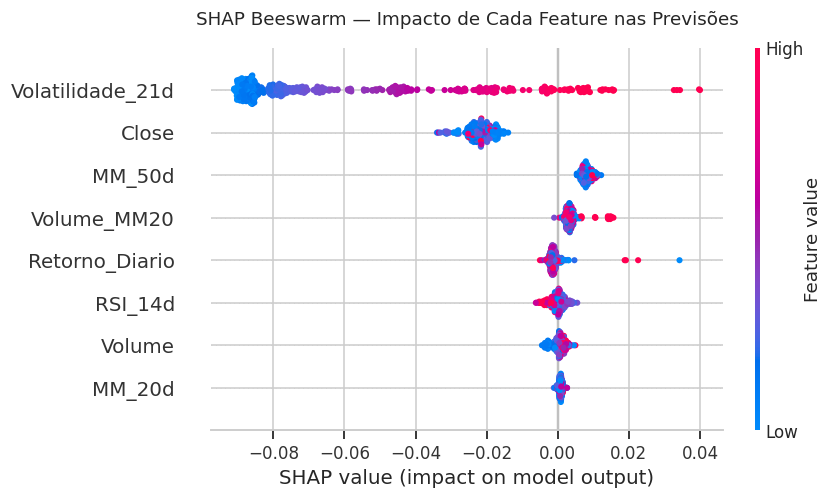

In [ ]:
# SHAP Beeswarm (distribuição dos impactos)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_s, feature_names=FEATURES, show=False)
plt.title("SHAP Beeswarm — Impacto de Cada Feature nas Previsões", pad=15)
plt.tight_layout()
plt.show()

📅 Explicando previsão para o índice de teste [10] — data: 2024-04-11


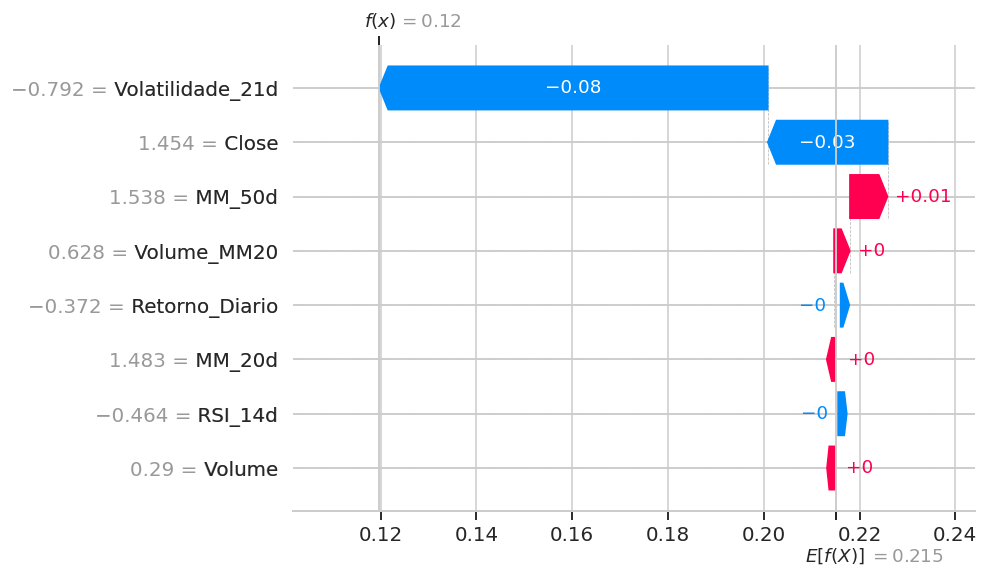

In [ ]:
# SHAP Waterfall
idx_exemplo = 10
print(f"📅 Explicando previsão para o índice de teste [{idx_exemplo}] "
      f"— data: {pd.to_datetime(datas_test[idx_exemplo]).date()}")

shap_exp = shap.Explanation(
    values=shap_values[idx_exemplo],
    base_values=explainer_shap.expected_value,
    data=X_test_s[idx_exemplo],
    feature_names=FEATURES
)
shap.plots.waterfall(shap_exp)

 Explicando previsão individual com LIME...
  Previsão XGBoost : 0.11974
  Valor real       : 0.12429


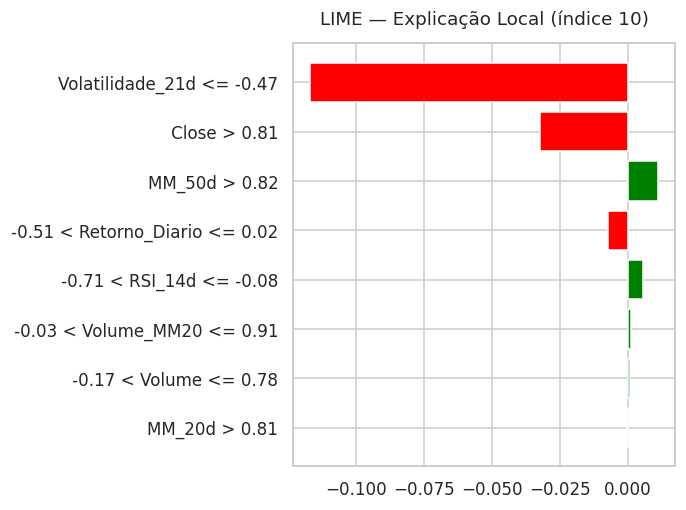

In [ ]:
#7.2 LIME
print(" Explicando previsão individual com LIME...")

explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_s,
    feature_names=FEATURES,
    mode="regression",
    random_state=42
)

instancia = X_test_s[idx_exemplo]
exp_lime  = explainer_lime.explain_instance(
    instancia,
    modelo_xgb.predict,
    num_features=len(FEATURES)
)

print(f"  Previsão XGBoost : {modelo_xgb.predict(instancia.reshape(1,-1))[0]:.5f}")
print(f"  Valor real       : {y_test[idx_exemplo]:.5f}")
exp_lime.as_pyplot_figure()
plt.title(f"LIME — Explicação Local (índice {idx_exemplo})", pad=12)
plt.tight_layout()
plt.show()

In [ ]:

melhor = df_resultados.iloc[0]
print("=" * 62)
print("  RELATÓRIO FINAL — TCC Lorrana E. A. Pereira")
print(f"  Gerado em: {datetime.now().strftime('%d/%m/%Y %H:%M')}")
print("=" * 62)
print(f"\n  Ativo analisado : IBOVESPA (^BVSP)")
print(f"  Período         : {DATA_INICIO} → {DATA_FIM}")
print(f"  Amostras treino : {X_train.shape[0]}")
print(f"  Amostras teste  : {X_test.shape[0]}")
print(f"  Variável-alvo   : Volatilidade histórica (21 dias) — t+1")
print(f"\n  {'Modelo':<20} {'RMSE':>10}  {'MAE':>10}  {'R²':>8}")
print("  " + "-"*52)
for _, row in df_resultados.iterrows():
    flag = " ⭐" if row["Modelo"] == melhor["Modelo"] else ""
    print(f"  {row['Modelo']:<20} {row['RMSE']:>10.5f}  {row['MAE']:>10.5f}  {row['R2']:>8.4f}{flag}")
print(f"\n  Melhor modelo   : {melhor['Modelo']} (menor RMSE)")
print("=" * 62)

  RELATÓRIO FINAL — TCC Lorrana E. A. Pereira
  Gerado em: 31/03/2026 12:00

  Ativo analisado : IBOVESPA (^BVSP)
  Período         : 2016-01-01 → 2026-03-31
  Amostras treino : 1992
  Amostras teste  : 499
  Variável-alvo   : Volatilidade histórica (21 dias) — t+1

  Modelo                     RMSE         MAE        R²
  ----------------------------------------------------
  XGBoost                 0.01335     0.00959    0.9002 ⭐
  LightGBM                0.01427     0.01049    0.8860
  Rede Neural (MLP)       0.01750     0.01333    0.8286

  Melhor modelo   : XGBoost (menor RMSE)


---
##  Dashboard Interativo

AINDA VOU TRABALHAR NESSA PARTE
